
# Lecture 26 — Hardware Solutions for RAW Hazards: Data Forwarding

**Professor:** Dr. Janibul Bashir  
**Lecture:** [Hardware Solution for RAW Dependency: Data Forwarding](https://youtu.be/kHxP9rb_CEU?utm_source=chatgpt.com)  
**Duration:** Approximately 38 minutes  
**Transcript:** Actual vidIQ transcript retrieved

---

## Lecture Overview

According to the professor's transcript:

| Timestamp | Topic |
|---|---|
| 0:00–9:06 | Hardware stalling and insertion of bubbles |
| 9:06–15:46 | Fundamental idea of data forwarding |
| 15:46–27:27 | Numerical example and EX-to-EX forwarding |
| 27:27–35:50 | Forwarding hardware: comparators and multiplexers |
| 35:50–37:41 | Other forwarding paths and final comparison |

---

## 1. Why Do We Need Forwarding?

Consider:

```asm
I1: add x2, x3, x4
I2: add x5, x2, x6
```

We know this is a **RAW dependency on `x2`**.

In the professor's earlier model:

- I1 calculates its result in EX.
- I1 writes that result into `x2` in WB.
- I2 waits until I1 completes WB.

The penalty is **three cycles**.

But there's a crucial observation:

**The ALU calculates the correct value in EX, two stages before WB. Why wait until WB if we can send that value directly to the instruction that needs it?**

That's the entire reasoning behind forwarding.

---

## 2. Data Forwarding — Definition

> **Data forwarding (bypassing)** is a hardware technique in which a result generated by one instruction is sent directly to a dependent instruction's execution unit without waiting for the result to be written into the register file.

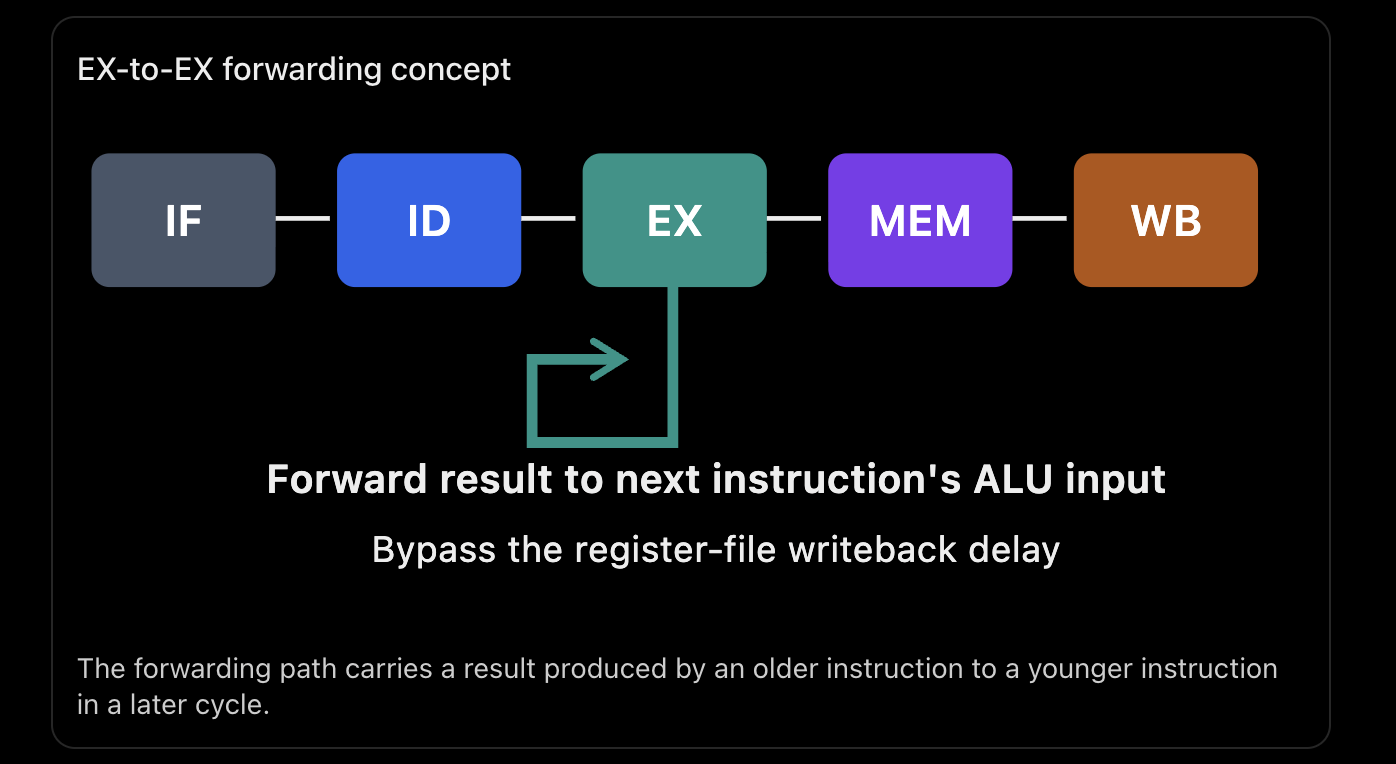
*The forwarding path carries a result produced by an older instruction to a younger instruction in a later cycle.*

---

## 3. Professor's Numerical Example

**Transcript:** Approximately 16:02–26:22

Given:

$$
x2=1,\quad x3=2,\quad x4=3,\quad x6=5
$$

Instructions:

```asm
I1: add x2, x3, x4
I2: add x5, x2, x6
```

### 3.1 Step 1 — Execute I1

$$
x2=x3+x4=2+3=\boxed{5}
$$

I1 calculates **5** in its EX stage.

However, the register file still contains the old `x2 = 1` until WB.

### 3.2 Step 2 — Execute I2 Without Forwarding

If I2 incorrectly uses the old register value:

$$
x5=1+5=\boxed{6}
$$

That's wrong.

The required result is:

$$
x5=5+5=\boxed{10}
$$

### 3.3 Step 3 — Execute I2 With Forwarding

The processor takes the result **5** generated by I1 and delivers it directly to I2's ALU input.

Therefore:

$$
x5=
\underbrace{5}_{\text{Forwarded result}}
+
\underbrace{5}_{x6}
$$

$$
\boxed{x5=10}
$$

No three-cycle wait is necessary.

---

## 4. Pipeline Diagram With Forwarding

| Instruction | C1 | C2 | C3 | C4 | C5 | C6 |
|---|---|---|---|---|---|---|
| I1: ADD | IF | ID | EX | MEM | WB | — |
| I2: ADD | — | IF | ID | EX | MEM | WB |

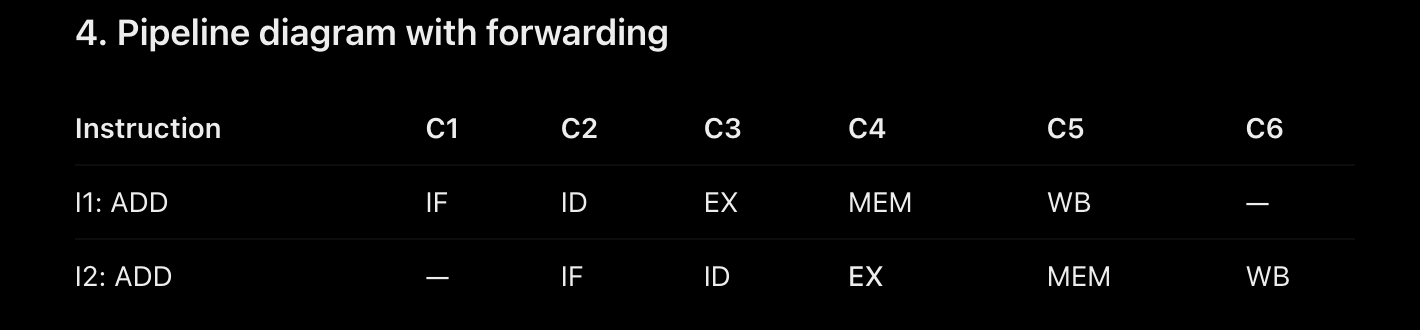

At the end of cycle 3, I1 has produced its ALU result.

In cycle 4:

- I1 is in MEM.
- I2 is in EX.
- I2 receives I1's result from the previous cycle's pipeline register through a forwarding path.

Notice that I2 may have read the stale `x2 = 1` in ID.

The **forwarding multiplexer replaces that stale operand before it enters the ALU**.

That is the important implementation detail.

### 4.1 Compare the Penalty

| Model | RAW Penalty |
|---|---|
| No forwarding; wait until after WB | 3 cycles |
| EX-to-EX forwarding for adjacent ALU instructions | **0 cycles** |

So forwarding improves both correctness and performance.

---

## 5. How Does the Forwarding Hardware Work?

**Transcript:** Approximately 27:27–35:50

We need to select the correct input for each ALU operand.

Suppose the next instruction has:

- `rs1`: First source register.
- `rs2`: Second source register.

The previous instruction has:

- `rd`: Destination register.
- `ALUResult`: Result calculated in EX.

### 5.1 Forwarding Comparator Logic

For operand 1:

$$
ForwardA=(rs1=rd_{\text{previous}})
$$

For operand 2:

$$
ForwardB=(rs2=rd_{\text{previous}})
$$

Each comparison produces a control signal for a multiplexer.

### 5.2 Simplified Two-Input Forwarding Hardware

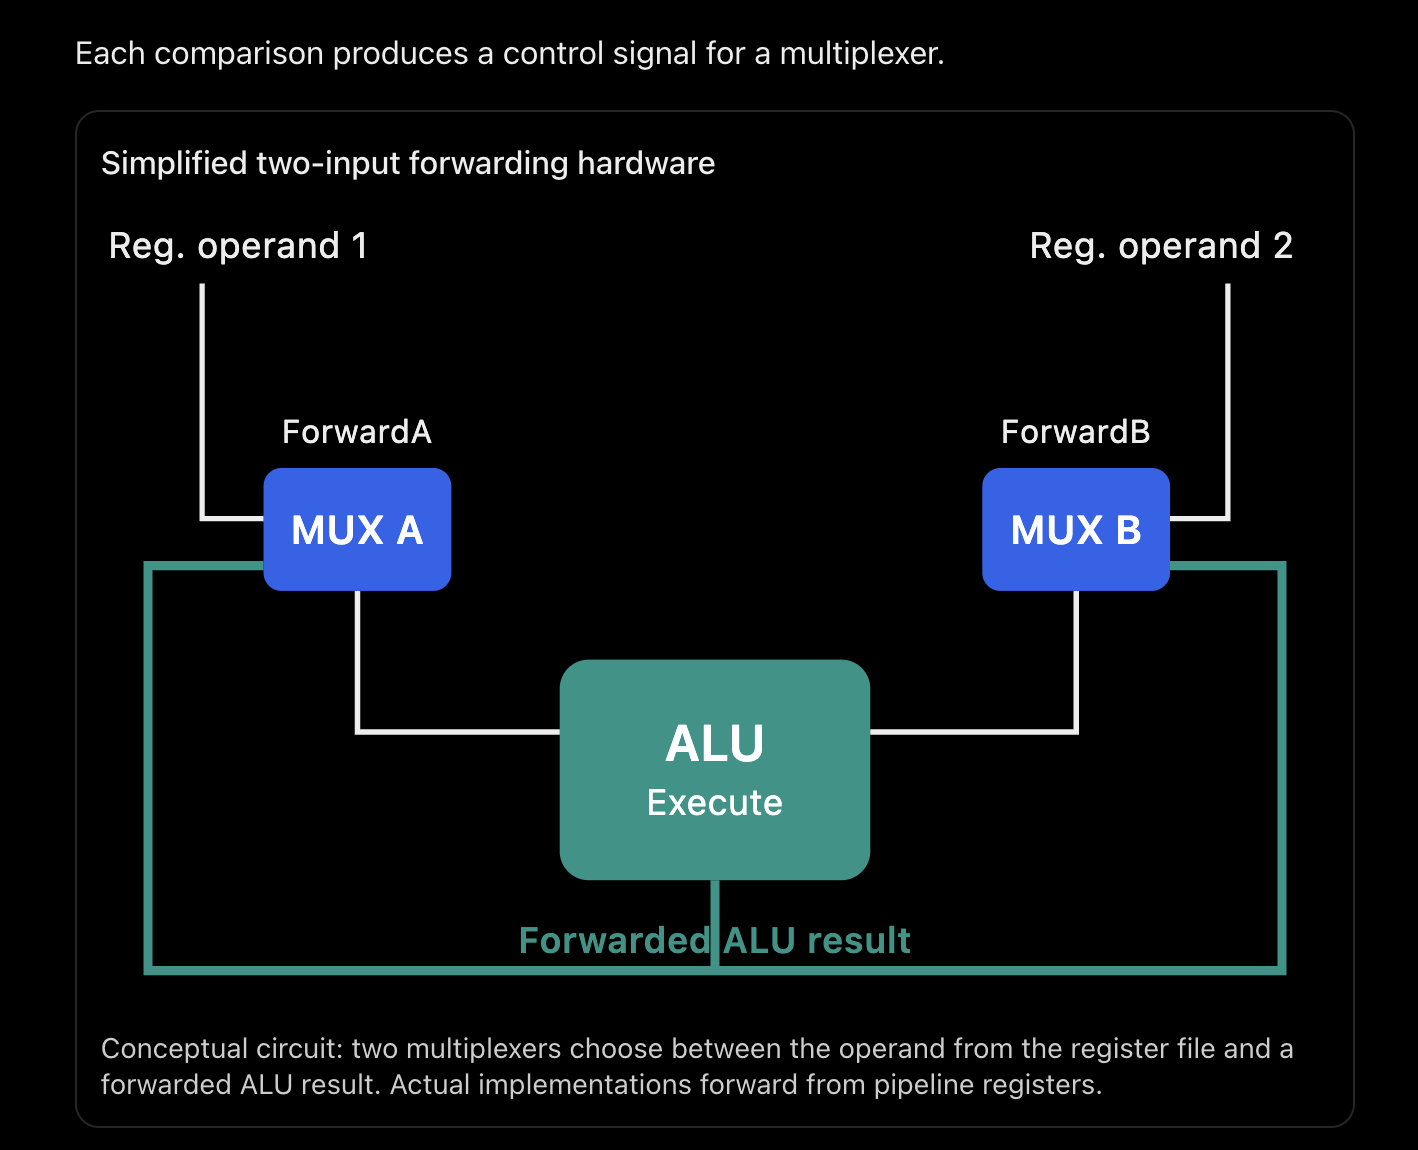

*Conceptual circuit: Two multiplexers choose between the operand from the register file and a forwarded ALU result. Actual implementations forward from pipeline registers.*

### 5.3 Multiplexer Truth Table

| Comparator Output | ALU Operand Selected |
|---|---|
| 0 | Value read from register file |
| 1 | Forwarded result |

### 5.4 Professor's Example — Forwarding Control Signals

Consider:

```asm
I1: add x2, x3, x4
I2: add x5, x2, x6
```

I1 destination is `x2`.

I2 source registers are:

- `rs1 = x2`
- `rs2 = x6`

Therefore:

$$
ForwardA=(x2=x2)=1
$$

$$
ForwardB=(x6=x2)=0
$$

Thus the ALU receives:

- **Operand A:** Forwarded result = 5.
- **Operand B:** Register value `x6` = 5.

The ALU computes:

$$
5+5=\boxed{10}
$$

> 📌 **Important implementation condition:** Forwarding is permitted only if the older instruction actually writes a register and its destination isn't `x0`.

More complete forwarding hardware must also select the **newest matching result** when several older instructions write the same register.

---

## 6. Does Forwarding Always Remove Every RAW Stall?

**No.**

The professor explicitly mentions other forwarding paths, including:

- MEM-to-EX
- WB-to-EX

### 6.1 The Load-Use Hazard

Consider:

```asm
I1: lw  x5, 0(x10)
I2: add x6, x5, x7
```

For `lw`, the required data isn't produced by the ALU in EX.

EX calculates the **memory address**; the loaded value becomes available after the MEM stage.

So the immediately following `add` usually cannot receive the data early enough for its scheduled EX cycle.

In the conventional five-stage pipeline, even with forwarding, this load-use hazard typically needs **one stall cycle**.

### 6.2 Typical Forwarding Results

| RAW Dependency | Typical Forwarding Result |
|---|---|
| ADD → ADD | Zero stalls |
| SUB → ADD | Zero stalls |
| ADD → SUB | Zero stalls |
| LOAD → Immediately dependent ADD | **One stall** |

The exact penalty depends on the pipeline implementation.

---

## 7. Lecture 26 — Exam Revision

| Technique | How It Works | Improves Useful IPC? |
|---|---|---|
| Hardware stalling | Freezes earlier pipeline stages and injects bubbles | No |
| Software NOP insertion | Compiler inserts harmless instructions | No |
| Instruction scheduling | Compiler rearranges useful independent instructions | Yes, when successful |
| Data forwarding | Bypasses register-file WB by directly supplying results | Yes, for hazards it resolves |

### Most Important Definition

> 📌 **Data forwarding** is a hardware technique used to resolve RAW dependencies by passing an available result directly to a dependent instruction's functional-unit input.

---


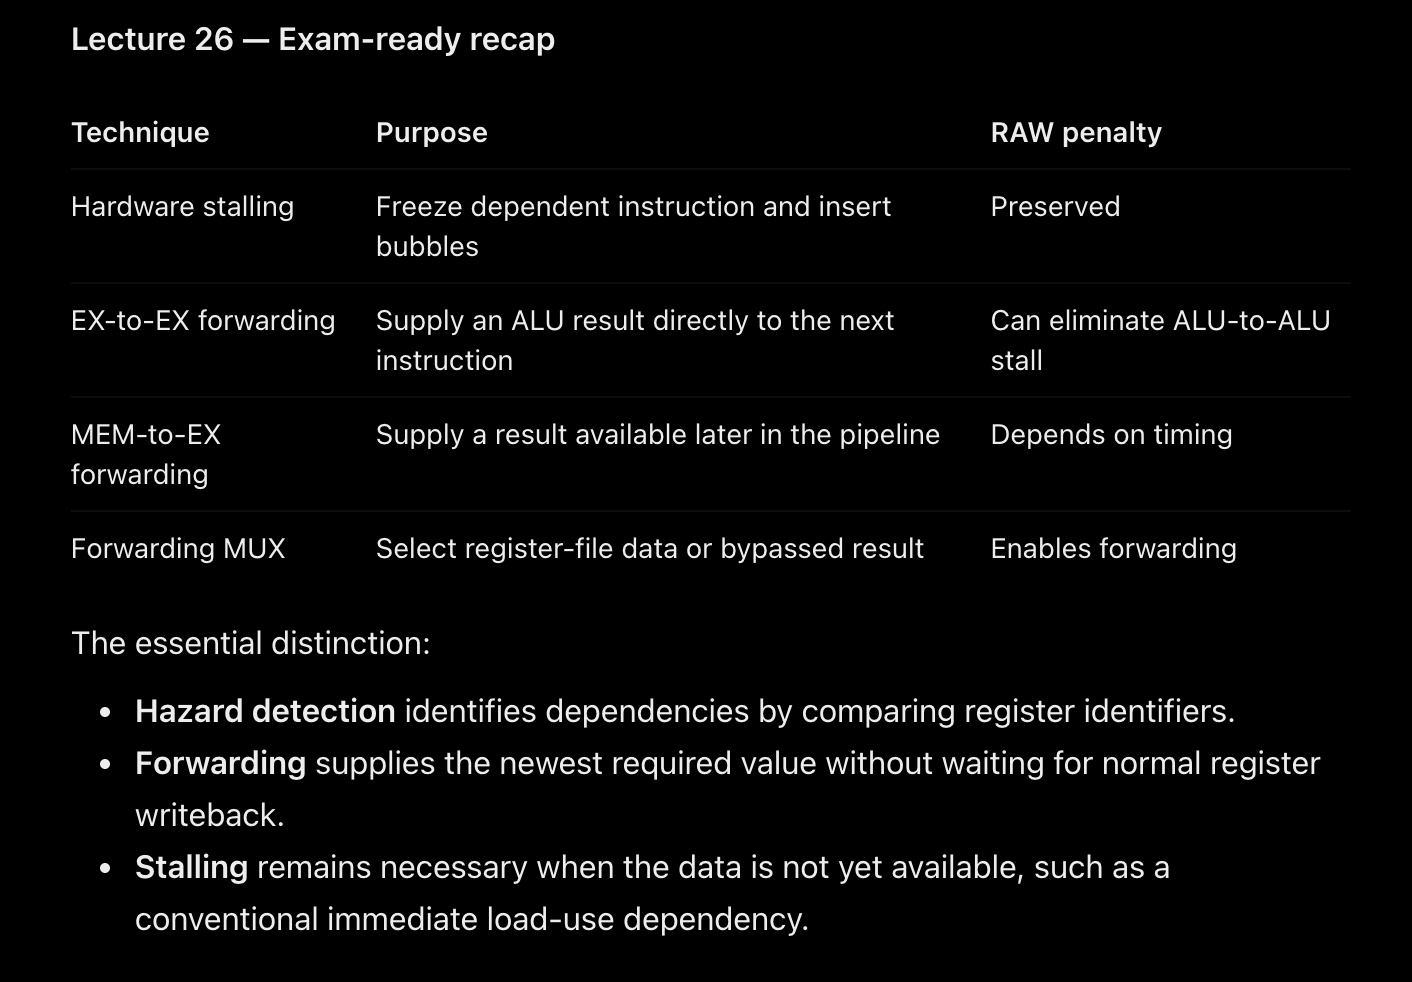